# 🌿 Spinach Leaf Classification — XGBoost
**Goal:** Classify spinach leaf images as **BIG LEAF** or **SMALL LEAF**

## Folder Structure
```
D:\Spinach_Leaf_Classification\
├── dataset\
│   └── model_ready\             ← Already created by Custom CNN notebook
│
├── models\
│   └── xgboost_model.json       ← Saved after Cell 3
│
└── results\
    └── xgboost\                 ← ALL XGBoost results here
        ├── confusion_matrix.png
        ├── feature_importance.png
        └── results_summary.csv
```

## Cell 1 — Imports & Paths

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from tqdm.notebook import tqdm

# ── PATHS ──────────────────────────────────────────────────
ROOT       = Path(r"D:\Spinach_Leaf_Classification")
DATA_DIR   = ROOT / "dataset" / "model_ready"
MODELS     = ROOT / "models"
XGB_RESULTS = ROOT / "results" / "xgboost"

MODELS.mkdir(exist_ok=True)
XGB_RESULTS.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 64   # resize for feature extraction
print("Paths ready.")
print("Cell 1 complete.")

Paths ready.
Cell 1 complete.


## Cell 2 — Feature Extraction
Extracts HOG + colour histogram + texture features from each image.

In [2]:
from skimage.feature import hog
from skimage import color

def extract_features(image_path):
    """Extract HOG + colour histogram + texture features."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None

    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    # ── HOG features ───────────────────────────────────────
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hog_feats = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=False
    )

    # ── Colour histogram (HSV) ──────────────────────────────
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [32], [0, 180]).flatten()
    hist_s = cv2.calcHist([hsv], [1], None, [32], [0, 256]).flatten()
    hist_v = cv2.calcHist([hsv], [2], None, [32], [0, 256]).flatten()
    hist_h /= (hist_h.sum() + 1e-7)
    hist_s /= (hist_s.sum() + 1e-7)
    hist_v /= (hist_v.sum() + 1e-7)

    # ── Texture: mean & std per channel ────────────────────
    texture = []
    for c in range(3):
        ch = img[:, :, c].astype(np.float32)
        texture.extend([ch.mean(), ch.std()])

    return np.concatenate([hog_feats, hist_h, hist_s, hist_v, texture])


def load_split(split_name):
    """Load all images from a split, return features & labels."""
    split_dir = DATA_DIR / split_name
    X, y = [], []
    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue
        for img_path in tqdm(list(class_dir.glob("*.*")), desc=f"{split_name}/{class_dir.name}"):
            feats = extract_features(img_path)
            if feats is not None:
                X.append(feats)
                y.append(class_dir.name)
    return np.array(X), np.array(y)


print("Extracting train features...")
X_train, y_train = load_split("train")

print("Extracting validation features...")
X_val, y_val = load_split("validation")

print("Extracting test features...")
X_test, y_test = load_split("test")

# Combine train + val for final training
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

# Encode labels
le = LabelEncoder()
le.fit(y_trainval)
y_trainval_enc = le.transform(y_trainval)
y_test_enc     = le.transform(y_test)

print(f"\nFeature vector size : {X_train.shape[1]}")
print(f"Train+Val samples   : {len(X_trainval)}")
print(f"Test samples        : {len(X_test)}")
print(f"Classes             : {le.classes_}")
print("Cell 2 complete.")

Extracting train features...


train/Big:   0%|          | 0/255 [00:00<?, ?it/s]

train/Small:   0%|          | 0/255 [00:00<?, ?it/s]

Extracting validation features...


validation/Big:   0%|          | 0/22 [00:00<?, ?it/s]

validation/Small:   0%|          | 0/23 [00:00<?, ?it/s]

Extracting test features...


test/Big:   0%|          | 0/23 [00:00<?, ?it/s]

test/Small:   0%|          | 0/22 [00:00<?, ?it/s]


Feature vector size : 1866
Train+Val samples   : 555
Test samples        : 45
Classes             : ['Big' 'Small']
Cell 2 complete.


## Cell 3 — Train XGBoost

In [3]:
xgb_model = xgb.XGBClassifier(
    n_estimators      = 300,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_weight  = 3,
    gamma             = 0.1,
    use_label_encoder = False,
    eval_metric       = "logloss",
    random_state      = 42,
    n_jobs            = -1
)

print("Training XGBoost...")
xgb_model.fit(
    X_trainval, y_trainval_enc,
    eval_set=[(X_test, y_test_enc)],
    verbose=50
)

# Save model
model_path = MODELS / "xgboost_model.json"
xgb_model.save_model(str(model_path))
print("\nModel saved to:", model_path)
print("Cell 3 complete.")

Training XGBoost...
[0]	validation_0-logloss:0.65270


C:\Users\CSE_SDPL\anaconda3\envs\drought\lib\site-packages\xgboost\training.py:200: UserWarning: [20:00:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[50]	validation_0-logloss:0.12768
[100]	validation_0-logloss:0.08362
[150]	validation_0-logloss:0.07355
[200]	validation_0-logloss:0.07182
[250]	validation_0-logloss:0.06975
[299]	validation_0-logloss:0.07111

Model saved to: D:\Spinach_Leaf_Classification\models\xgboost_model.json
Cell 3 complete.


## Cell 4 — Evaluate on Test Set

MODEL: XGBoost
Test images  : 45
Test accuracy: 97.78%

Classification Report:
              precision    recall  f1-score   support

         Big       0.96      1.00      0.98        23
       Small       1.00      0.95      0.98        22

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



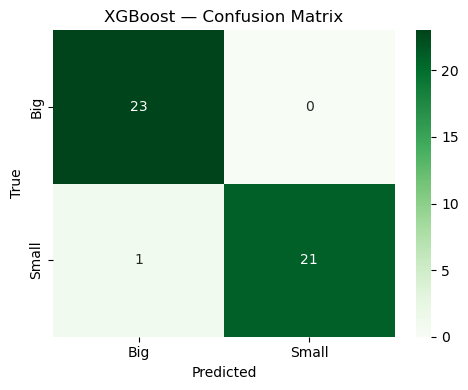

Confusion matrix saved: D:\Spinach_Leaf_Classification\results\xgboost\confusion_matrix.png
Cell 4 complete.


In [4]:
y_pred     = xgb_model.predict(X_test)
pred_names = le.inverse_transform(y_pred)
true_names = le.inverse_transform(y_test_enc)
class_names = list(le.classes_)

test_acc = accuracy_score(y_test_enc, y_pred)

print("=" * 55)
print("MODEL: XGBoost")
print("=" * 55)
print(f"Test images  : {len(X_test)}")
print(f"Test accuracy: {test_acc*100:.2f}%")
print("\nClassification Report:")
print(classification_report(true_names, pred_names,
                             labels=class_names, target_names=class_names,
                             zero_division=0))

# Confusion matrix
cm = confusion_matrix(true_names, pred_names, labels=class_names)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.title("XGBoost — Confusion Matrix")
plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout()
cm_path = XGB_RESULTS / "confusion_matrix.png"
plt.savefig(cm_path, dpi=120)
plt.show()
print("Confusion matrix saved:", cm_path)

xgb_results = {"model": "XGBoost", "test_accuracy": test_acc}
print("Cell 4 complete.")

## Cell 5 — Feature Importance Plot

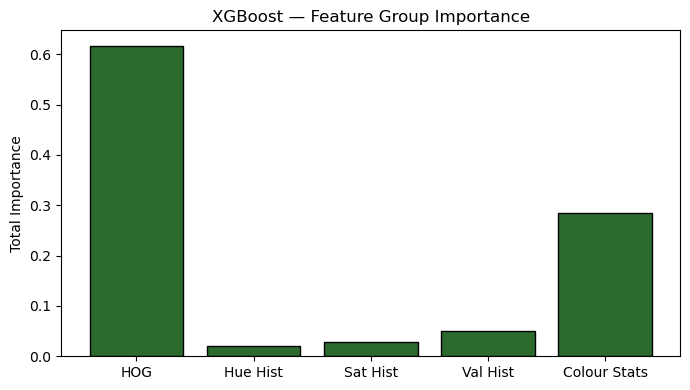

Feature importance saved: D:\Spinach_Leaf_Classification\results\xgboost\feature_importance.png
Cell 5 complete.


In [5]:
importance = xgb_model.feature_importances_

# Group by feature block for readability
hog_size   = len(importance) - 32 - 32 - 32 - 6
blocks = {
    "HOG":          importance[:hog_size].sum(),
    "Hue Hist":     importance[hog_size          : hog_size+32].sum(),
    "Sat Hist":     importance[hog_size+32        : hog_size+64].sum(),
    "Val Hist":     importance[hog_size+64        : hog_size+96].sum(),
    "Colour Stats": importance[hog_size+96:].sum()
}

plt.figure(figsize=(7, 4))
plt.bar(blocks.keys(), blocks.values(), color="#2d6a2d", edgecolor="black")
plt.title("XGBoost — Feature Group Importance")
plt.ylabel("Total Importance")
plt.tight_layout()
fi_path = XGB_RESULTS / "feature_importance.png"
plt.savefig(fi_path, dpi=120)
plt.show()
print("Feature importance saved:", fi_path)
print("Cell 5 complete.")

## Cell 6 — Save Results Summary

In [6]:
summary = pd.DataFrame([xgb_results])
summary["accuracy_percent"] = summary["test_accuracy"] * 100
summary_path = XGB_RESULTS / "results_summary.csv"
summary.to_csv(summary_path, index=False)

print("XGBOOST RESULTS")
print("=" * 50)
print(summary[["model", "accuracy_percent"]].to_string(index=False))
print("\nAll files saved to:", XGB_RESULTS)
print("  - confusion_matrix.png   (test set confusion matrix)")
print("  - feature_importance.png (feature group importance)")
print("  - results_summary.csv    (final accuracy)")
print("Model saved to:", MODELS / "xgboost_model.json")
print("\nProject complete!")

XGBOOST RESULTS
  model  accuracy_percent
XGBoost         97.777778

All files saved to: D:\Spinach_Leaf_Classification\results\xgboost
  - confusion_matrix.png   (test set confusion matrix)
  - feature_importance.png (feature group importance)
  - results_summary.csv    (final accuracy)
Model saved to: D:\Spinach_Leaf_Classification\models\xgboost_model.json

Project complete!
